# M4 — Fine-tuning phase 2 (Colab, images locales)

Reprise du **meilleur checkpoint de la phase 1** (`M4_FT_B5_LR1e-5_best.keras`). Bloc 5 VGG16 dégelé, LR `1e-6`, maximum 5 epochs, patience 2. Validation uniquement, aucun accès au test.

**Images :** attendues dans `/content/COVID-19_Radiography_Dataset`. La copie Drive → local est commentée par défaut : décommenter uniquement après un changement de runtime.


In [1]:
from google.colab import drive
drive.mount('/content/drive')
from pathlib import Path
import shutil, time, json, zipfile
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras.models import load_model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, CSVLogger
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

tf.keras.utils.set_random_seed(42)
PROJECT_DIR = Path('/content/drive/MyDrive/Apprentissage/DS/projet')
DRIVE_DATASET_ROOT = PROJECT_DIR / 'COVID-19_Radiography_Dataset'
DATASET_ROOT = Path('/content/COVID-19_Radiography_Dataset')
OUTPUT_DIR = PROJECT_DIR / 'M4_finetuning'
OUTPUT_DIR.mkdir(exist_ok=True)
CHECKPOINT = OUTPUT_DIR / 'M4_FT_B5_LR1e-5_best.keras'
if not CHECKPOINT.is_file():
    raise FileNotFoundError(f'Checkpoint phase 1 introuvable : {CHECKPOINT}')
print('GPU :', tf.config.list_physical_devices('GPU'))

# Copie Drive -> /content (désactivée par défaut : dataset déjà local dans ce runtime).
# Si nouveau runtime, décommenter le bloc suivant et relancer cette cellule :
if not DATASET_ROOT.exists():
     start = time.perf_counter()
     shutil.copytree(DRIVE_DATASET_ROOT, DATASET_ROOT)
     print(f'Copie locale terminée en {(time.perf_counter()-start)/60:.1f} min')

if not DATASET_ROOT.is_dir():
    raise FileNotFoundError(
        f'Dataset local absent : {DATASET_ROOT}. '
        'Décommenter la copie Drive -> local ci-dessus, puis relancer.')
print('Dataset local présent :', DATASET_ROOT)


Mounted at /content/drive
GPU : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Copie locale terminée en 15.4 min
Dataset local présent : /content/COVID-19_Radiography_Dataset


In [2]:
train_df = pd.read_csv(PROJECT_DIR / 'train.csv')
val_df = pd.read_csv(PROJECT_DIR / 'validation.csv')

# Les chemins CSV sont ceux du PC Windows ; on conserve seulement la partie
# après COVID-19_Radiography_Dataset, comme dans E2/E3 du binôme.
def local_filepath(original):
    normalized = str(original).replace('\\', '/')
    marker = 'COVID-19_Radiography_Dataset/'
    if marker not in normalized:
        raise ValueError(f'Chemin CSV inattendu : {original}')
    return str(DATASET_ROOT / normalized.split(marker, 1)[1])

train_df['filepath'] = train_df['filepath'].map(local_filepath)
val_df['filepath'] = val_df['filepath'].map(local_filepath)
# Deux vérifications rapides pour éviter un fit avec 0 image.
assert Path(train_df['filepath'].iloc[0]).is_file(), train_df['filepath'].iloc[0]
assert Path(val_df['filepath'].iloc[0]).is_file(), val_df['filepath'].iloc[0]
print('Train :', len(train_df), 'Validation :', len(val_df))


Train : 13545 Validation : 3387


In [3]:
classes = sorted(train_df['class'].dropna().unique().tolist())
train_df['class'] = train_df['class'].astype(str)
val_df['class'] = val_df['class'].astype(str)
datagen = ImageDataGenerator(preprocessing_function=preprocess_input)
train_generator = datagen.flow_from_dataframe(train_df, x_col='filepath', y_col='class', classes=classes,
    target_size=(224,224), color_mode='rgb', class_mode='categorical', batch_size=32, shuffle=True, seed=42)
val_generator = datagen.flow_from_dataframe(val_df, x_col='filepath', y_col='class', classes=classes,
    target_size=(224,224), color_mode='rgb', class_mode='categorical', batch_size=32, shuffle=False)
print('Classes :', val_generator.class_indices)

Found 13545 validated image filenames belonging to 4 classes.
Found 3387 validated image filenames belonging to 4 classes.
Classes : {'COVID': 0, 'Lung_Opacity': 1, 'Normal': 2, 'Viral Pneumonia': 3}


In [4]:
# Phase 2 : reprendre le meilleur checkpoint de phase 1, sans toucher à celui-ci.
EXPERIMENT_NAME = 'M4_FT2_B5_LR1e-6'
LEARNING_RATE = 1e-6
EPOCHS = 5
UNFREEZE_BLOCK = 5

# Phase 2 : checkpoint du meilleur modèle de phase 1 (pas le M4 initial).
# Modèle sauvegardé par la même version Colab de Keras : chargement direct.
model = load_model(CHECKPOINT, compile=False)
base_model = model.layers[0]  # VGG16 dans Sequential
base_model.trainable = True
for layer in base_model.layers:
    layer.trainable = layer.name.startswith(f'block{UNFREEZE_BLOCK}_')
print('Couches VGG16 entraînables :', [l.name for l in base_model.layers if l.trainable])

model.compile(optimizer=Adam(learning_rate=LEARNING_RATE),
              loss='categorical_crossentropy', metrics=['accuracy'])
BEST_PATH = OUTPUT_DIR / f'{EXPERIMENT_NAME}_best.keras'
callbacks = [
    EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True),
    ModelCheckpoint(str(BEST_PATH), monitor='val_loss', save_best_only=True),
    CSVLogger(str(OUTPUT_DIR / f'{EXPERIMENT_NAME}_history.csv')),
]


Couches VGG16 entraînables : ['block5_conv1', 'block5_conv2', 'block5_conv3', 'block5_pool']


In [5]:
history = model.fit(train_generator, validation_data=val_generator,
                    epochs=EPOCHS, callbacks=callbacks)
print('Meilleur checkpoint :', BEST_PATH)

Epoch 1/5
424/424 ━━━━━━━━━━━━━━━━━━━━ 112s 241ms/step - accuracy: 0.9763 - loss: 0.0726 - val_accuracy: 0.9365 - val_loss: 0.2160
Epoch 2/5
424/424 ━━━━━━━━━━━━━━━━━━━━ 91s 214ms/step - accuracy: 0.9757 - loss: 0.0638 - val_accuracy: 0.9356 - val_loss: 0.2069
Epoch 3/5
424/424 ━━━━━━━━━━━━━━━━━━━━ 94s 221ms/step - accuracy: 0.9812 - loss: 0.0583 - val_accuracy: 0.9371 - val_loss: 0.2064
Epoch 4/5
424/424 ━━━━━━━━━━━━━━━━━━━━ 90s 213ms/step - accuracy: 0.9821 - loss: 0.0542 - val_accuracy: 0.9333 - val_loss: 0.2103
Epoch 5/5
424/424 ━━━━━━━━━━━━━━━━━━━━ 93s 219ms/step - accuracy: 0.9849 - loss: 0.0488 - val_accuracy: 0.9368 - val_loss: 0.2218
Meilleur checkpoint : /content/drive/MyDrive/Apprentissage/DS/projet/M4_finetuning/M4_FT2_B5_LR1e-6_best.keras


106/106 ━━━━━━━━━━━━━━━━━━━━ 19s 172ms/step
                 precision    recall  f1-score   support

          COVID     0.9857    0.9551    0.9702       579
   Lung_Opacity     0.9150    0.8925    0.9036       977
         Normal     0.9272    0.9515    0.9392      1607
Viral Pneumonia     0.9821    0.9821    0.9821       224

       accuracy                         0.9371      3387
      macro avg     0.9525    0.9453    0.9488      3387
   weighted avg     0.9373    0.9371    0.9371      3387



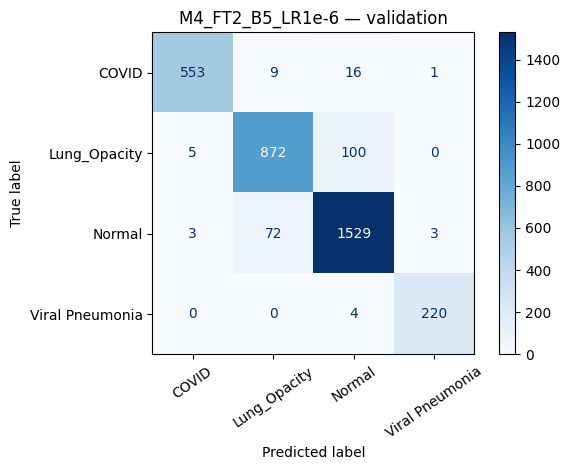

Recall COVID : 0.9550949913644214 F1 COVID : 0.9701754385964912


In [6]:
best_model = load_model(BEST_PATH)
val_generator.reset()
y_prob = best_model.predict(val_generator, verbose=1)
y_true = val_generator.classes
y_pred = np.argmax(y_prob, axis=1)
report = classification_report(y_true, y_pred, target_names=classes, output_dict=True, zero_division=0)
pd.DataFrame(report).T.to_csv(OUTPUT_DIR / f'{EXPERIMENT_NAME}_classification_report.csv')
pd.DataFrame({'y_true': y_true, 'y_pred': y_pred}).to_csv(OUTPUT_DIR / f'{EXPERIMENT_NAME}_predictions.csv', index=False)
print(classification_report(y_true, y_pred, target_names=classes, digits=4, zero_division=0))
cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(cm, display_labels=classes).plot(cmap='Blues', xticks_rotation=35)
plt.title(EXPERIMENT_NAME + ' — validation')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / f'{EXPERIMENT_NAME}_confusion_matrix.png', dpi=160, bbox_inches='tight')
plt.show()
print('Recall COVID :', report['COVID']['recall'], 'F1 COVID :', report['COVID']['f1-score'])

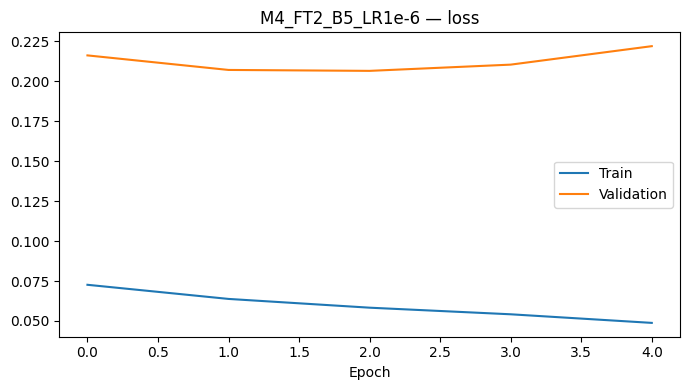

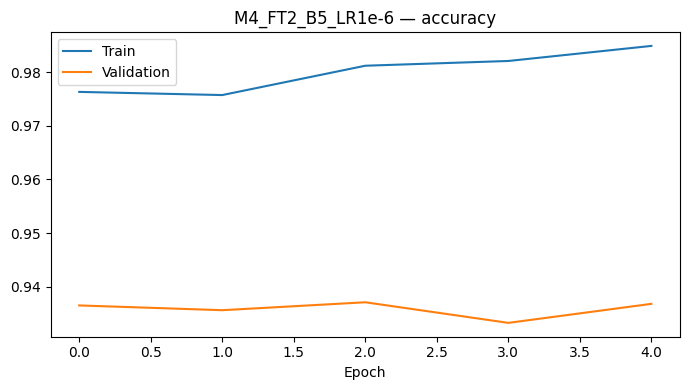

In [7]:
hist = pd.read_csv(OUTPUT_DIR / f'{EXPERIMENT_NAME}_history.csv')
for metric in ('loss', 'accuracy'):
    plt.figure(figsize=(7, 4))
    plt.plot(hist[metric], label='Train')
    plt.plot(hist['val_' + metric], label='Validation')
    plt.title(f'{EXPERIMENT_NAME} — {metric}')
    plt.xlabel('Epoch')
    plt.legend()
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f'{EXPERIMENT_NAME}_{metric}.png', dpi=160)
    plt.show()